# Top-N рекомендательная система на Collaborative Filtering

Данные: файлы из раздела «Финальная предобработка». Положительным считается любое взаимодействие (оценка), как в протоколе NCF.

Модели: Popularity (базовая линия), Item-kNN, User-kNN, PureSVD, ALS (implicit). Гиперпараметры подбираются на val, финальная проверка на test один раз.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds

D = Path("~/Workspace/ML_Project/data/processed").expanduser()
SEED = 42
K = 10

## 1. Загрузка и матрицы взаимодействий

In [3]:
train, val, test = (pd.read_csv(D / f"{s}.csv") for s in ["train", "val", "test"])
val_neg, test_neg = np.load(D / "val_neg.npy"), np.load(D / "test_neg.npy")
items = pd.read_csv(D / "items.csv").sort_values("iid").reset_index(drop=True)
users = pd.read_csv(D / "users.csv")
meta = json.load(open(D / "meta.json"))
n_users, n_items = meta["n_users"], meta["n_items"]
assert (items["iid"].to_numpy() == np.arange(n_items)).all()

def to_matrix(*dfs):
    d = pd.concat(dfs)
    return csr_matrix((np.ones(len(d), dtype=np.float32), (d["uid"].to_numpy(), d["iid"].to_numpy())),
                      shape=(n_users, n_items))

B_train = to_matrix(train)
B_trainval = to_matrix(train, val)
B_all = to_matrix(train, val, test)
print(f"users={n_users}, items={n_items}, train={len(train)}, val={len(val)}, test={len(test)}")
print(f"плотность B_train: {B_train.nnz / (n_users * n_items):.2%}")

users=602, items=2097, train=60419, val=7545, test=7545
плотность B_train: 4.79%


## 2. Метрики

Два протокола:
- **100 кандидатов** (как в NCF): настоящий фильм против 99 негативов из `*_neg.npy`, метрики HR@10 и NDCG@10. Ничьи считаются в среднем (иначе модели с множеством нулевых скоров получают бонус).
- **Полное ранжирование:** top-10 из всех фильмов, которых пользователь ещё не видел. Recall@10, NDCG@10 и Coverage (доля каталога, которая вообще попадает в рекомендации). Это более жёсткая и более честная оценка.

In [4]:
def sampled_metrics(S, df, neg, k=K):
    u = df["uid"].to_numpy()
    pos = S[u, df["iid"].to_numpy()]
    negs = S[u[:, None], neg]
    rank = (negs > pos[:, None]).sum(1) + 0.5 * (negs == pos[:, None]).sum(1)
    hit = (rank < k).astype(float)
    return hit.mean(), (hit / np.log2(rank + 2)).mean()


def topn(S, B_hist, k=K, seed=SEED):
    S = S.astype(np.float64) + np.random.default_rng(seed).random(S.shape) * 1e-9
    S[B_hist.nonzero()] = -np.inf
    top = np.argpartition(-S, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(S, top, 1), axis=1)
    return np.take_along_axis(top, order, 1)


def full_metrics(S, B_hist, df, k=K):
    rel = np.zeros((n_users, n_items), dtype=bool)
    rel[df["uid"].to_numpy(), df["iid"].to_numpy()] = True
    top = topn(S, B_hist, k)
    gains = np.take_along_axis(rel, top, 1)
    n_rel = rel.sum(1)
    m = n_rel > 0
    disc = 1 / np.log2(np.arange(2, k + 2))
    idcg = np.array([disc[:min(int(n), k)].sum() for n in n_rel])
    recall = (gains.sum(1)[m] / n_rel[m]).mean()
    ndcg = ((gains * disc).sum(1)[m] / idcg[m]).mean()
    coverage = len(np.unique(top[m])) / n_items
    return recall, ndcg, coverage


def evaluate(S, B_hist, df, neg):
    hr, ndcg_s = sampled_metrics(S, df, neg)
    rec, ndcg, cov = full_metrics(S, B_hist, df)
    return {"HR@10_100": hr, "NDCG@10_100": ndcg_s, "Recall@10": rec, "NDCG@10": ndcg, "Coverage": cov}

## 3. Модели

Каждая модель берёт бинарную матрицу «пользователь × фильм» и возвращает матрицу скоров той же формы: чем выше скор, тем сильнее рекомендация.

In [5]:
def popularity(B):
    return np.tile(np.asarray(B.sum(0)).ravel(), (B.shape[0], 1))


def item_similarity(B, k=50, shrink=10.0):
    C = (B.T @ B).toarray()
    norm = np.sqrt(np.diag(C))
    sim = C / np.maximum(np.outer(norm, norm) + shrink, 1e-12)
    np.fill_diagonal(sim, 0)
    if k < B.shape[1]:
        drop = np.argpartition(sim, -k, axis=1)[:, :-k]
        np.put_along_axis(sim, drop, 0, axis=1)
    return sim


def item_knn(B, k=50, shrink=10.0):
    return np.asarray(B @ item_similarity(B, k, shrink).T)


def user_knn(B, k=50):
    C = (B @ B.T).toarray()
    norm = np.sqrt(np.diag(C))
    sim = C / np.maximum(np.outer(norm, norm), 1e-12)
    np.fill_diagonal(sim, 0)
    drop = np.argpartition(sim, -k, axis=1)[:, :-k]
    np.put_along_axis(sim, drop, 0, axis=1)
    return np.asarray((B.T @ sim.T).T)


def pure_svd(B, factors=32):
    U, s, Vt = svds(B.astype(np.float64), k=factors, random_state=SEED)
    return (U * s) @ Vt


def als(B, factors=32, alpha=10.0, reg=30.0, iters=15):
    rng = np.random.default_rng(SEED)
    X = rng.normal(0, 0.01, (B.shape[0], factors))
    Y = rng.normal(0, 0.01, (B.shape[1], factors))
    Bu, Bi = B.tocsr(), B.T.tocsr()

    def solve(fixed, M):
        base = fixed.T @ fixed + reg * np.eye(factors)
        out = np.zeros((M.shape[0], factors))
        for r in range(M.shape[0]):
            idx = M.indices[M.indptr[r]:M.indptr[r + 1]]
            if len(idx) == 0:
                continue
            Yr = fixed[idx]
            out[r] = np.linalg.solve(base + alpha * Yr.T @ Yr, (1 + alpha) * Yr.sum(0))
        return out

    for _ in range(iters):
        X = solve(Y, Bu)
        Y = solve(X, Bi)
    return X @ Y.T

## 4. Подбор гиперпараметров на val (модель обучается на train, история пользователя = train)

In [6]:
models = {"Popularity": popularity, "ItemKNN": item_knn, "UserKNN": user_knn, "PureSVD": pure_svd, "ALS": als}
grid = {
    "Popularity": [{}],
    "ItemKNN": [{"k": k, "shrink": s} for k in (20, 50, 100) for s in (0, 10)],
    "UserKNN": [{"k": k} for k in (20, 50, 100)],
    "PureSVD": [{"factors": f} for f in (16, 32, 64)],
    "ALS": [{"factors": f, "alpha": a, "reg": r} for f in (16, 32) for a in (5, 20) for r in (10, 50)],
}

rows = []
for name, plist in grid.items():
    for params in plist:
        S = models[name](B_train, **params)
        rows.append({"model": name, "params": params, **evaluate(S, B_train, val, val_neg)})
val_res = pd.DataFrame(rows)

best = val_res.loc[val_res.groupby("model")["NDCG@10"].idxmax()].set_index("model")
best[["params", "HR@10_100", "NDCG@10_100", "Recall@10", "NDCG@10", "Coverage"]].round(4).sort_values("NDCG@10", ascending=False)

,params,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage
model,,,,,,
ItemKNN,"{'k': 20, 'shrink': 10}",0.4737,0.2592,0.0934,0.0988,0.3343
ALS,"{'factors': 16, 'alpha': 5, 'reg': 10}",0.4851,0.2643,0.0899,0.0932,0.3309
PureSVD,{'factors': 16},0.4701,0.2591,0.0843,0.0912,0.2542
UserKNN,{'k': 50},0.4509,0.2496,0.0804,0.0904,0.1202
Popularity,{},0.3229,0.1702,0.0510,0.0617,0.0410


## 5. Финальная оценка на test (модель переобучается на train+val, из рекомендаций исключается вся известная история)

In [7]:
rows = []
for name, r in best.iterrows():
    S = models[name](B_trainval, **r["params"])
    rows.append({"model": name, **evaluate(S, B_trainval, test, test_neg)})
test_res = pd.DataFrame(rows).set_index("model").sort_values("NDCG@10", ascending=False)
test_res.round(4)

,HR@10_100,NDCG@10_100,Recall@10,NDCG@10,Coverage
model,,,,,
ItemKNN,0.4195,0.2238,0.0785,0.0842,0.3362
PureSVD,0.4274,0.2286,0.0726,0.0823,0.2680
ALS,0.4331,0.2296,0.0789,0.0795,0.3448
UserKNN,0.3973,0.2138,0.0629,0.0754,0.1373
Popularity,0.2850,0.1453,0.0404,0.0524,0.0453


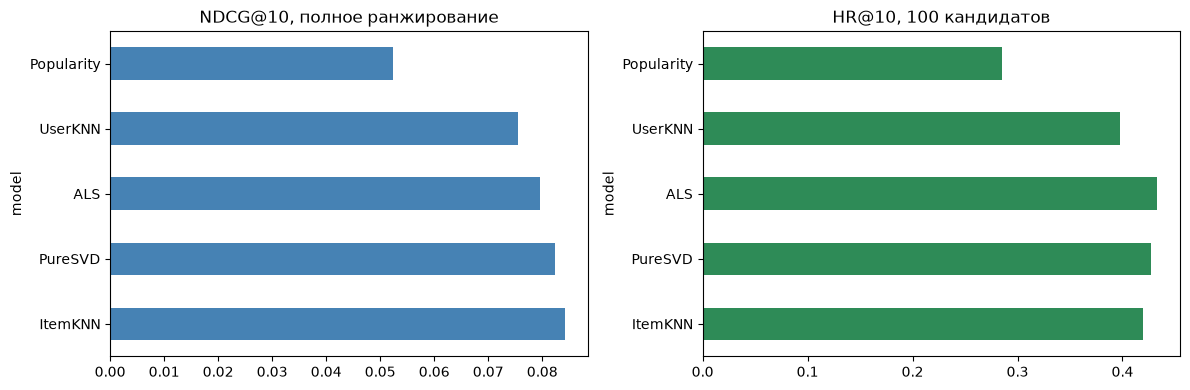

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
test_res["NDCG@10"].plot(kind="barh", ax=ax[0], color="steelblue")
ax[0].set(title="NDCG@10, полное ранжирование", xlabel="")
test_res["HR@10_100"].plot(kind="barh", ax=ax[1], color="seagreen")
ax[1].set(title="HR@10, 100 кандидатов", xlabel="")
plt.tight_layout()
plt.show()

In [9]:
import mlflow

mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("Сollaborative_Filtering")

METRICS = {
    "HR@10_100": f"hr_N_{K}_100cand",
    "NDCG@10_100": f"ndcg_N_{K}_100cand",
    "Recall@10": f"recall_N_{K}",
    "NDCG@10": f"ndcg_N_{K}",
    "Coverage": "coverage",
}

with mlflow.start_run(run_name="Recsys_CF_comparison") as parent_run:
    mlflow.log_param("top_k", K)
    mlflow.log_param("n_models", len(best))
    mlflow.log_param("n_neg_eval", meta["n_neg_eval"])
    mlflow.log_param("best_model_val", best["NDCG@10"].idxmax())
    mlflow.log_param("test_fit_on", "train+val")
    mlflow.log_figure(fig, "test_comparison.png")
    mlflow.log_text(val_res.to_csv(index=False), "val_grid_search.csv")

    for name in best.index:
        with mlflow.start_run(run_name=f"{name}_CF", nested=True):
            mlflow.log_param("model_type", name)
            hp = {("n_neighbors" if p == "k" else p): v for p, v in best.loc[name, "params"].items()}
            if hp:
                mlflow.log_params(hp)
            for col, key in METRICS.items():
                mlflow.log_metric(f"val_{key}", float(best.loc[name, col]))
                mlflow.log_metric(f"test_{key}", float(test_res.loc[name, col]))

🏃 View run ALS_CF at: http://localhost:5000/#/experiments/2/runs/83f229e2661b45c2911f492684f09e78
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run ItemKNN_CF at: http://localhost:5000/#/experiments/2/runs/d4a7f184bbe7453c9def8fc9c190bb23
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run Popularity_CF at: http://localhost:5000/#/experiments/2/runs/67be2c8b39ec4db3858b5d377a89ce22
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run PureSVD_CF at: http://localhost:5000/#/experiments/2/runs/b3577a9e69414f5984942bc0468b8dd7
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run UserKNN_CF at: http://localhost:5000/#/experiments/2/runs/fb32f71f6ddb45c58d72465a5ec1378d
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run Recsys_CF_comparison at: http://localhost:5000/#/experiments/2/runs/6d3654e825854fb3812cf405c0f0668b
🧪 View experiment at: http://localhost:5000/#/experiments/2


## 6. Рекомендательная система

Финальная модель обучается на всей известной истории (train+val+test) и выдаёт top-N по каждому пользователю. Лучшая модель выбирается по NDCG@10 на val.

In [10]:
best_name = best["NDCG@10"].idxmax()
best_params = best.loc[best_name, "params"]
print("Лучшая модель:", best_name, best_params)

S_final = models[best_name](B_all, **best_params)
uid_of = dict(zip(users["userId"], users["uid"]))
all_df = pd.concat([train, val, test])


def recommend(user_id, n=10):
    u = uid_of[user_id]
    s = S_final[u].astype(np.float64).copy()
    s[B_all[u].indices] = -np.inf
    top = np.argsort(-s)[:n]
    out = items.loc[top, ["iid", "movieId", "title", "year", "genres"]].copy()
    out["score"] = s[top]
    return out.reset_index(drop=True)


def history(user_id, n=10):
    h = all_df[all_df["userId"] == user_id].sort_values("rating", ascending=False).head(n)
    return h.merge(items[["iid", "title", "genres"]], on="iid")[["title", "genres", "rating"]]


demo_user = users["userId"].iloc[0]
history(demo_user)

Лучшая модель: ItemKNN {'k': 20, 'shrink': 10}


,title,genres,rating
0,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Sci-Fi,5.0
1,Bambi (1942),Animation|Children|Drama,5.0
2,Gladiator (2000),Action|Adventure|Drama,5.0
3,American Beauty (1999),Drama|Romance,5.0
4,Bottle Rocket (1996),Adventure|Comedy|Crime|Romance,5.0
5,Tommy Boy (1995),Comedy,5.0
6,Billy Madison (1995),Comedy,5.0
7,SLC Punk! (1998),Comedy|Drama,5.0
8,Grumpy Old Men (1993),Comedy,5.0
9,Dumb & Dumber (Dumb and Dumber) (1994),Adventure|Comedy,5.0


In [11]:
recommend(demo_user)

,iid,movieId,title,year,genres,score
0,262,589,Terminator 2: Judgment Day (1991),1991,Action|Sci-Fi,9.442907
1,943,2762,"Sixth Sense, The (1999)",1999,Drama|Horror|Mystery,9.402267
2,326,858,"Godfather, The (1972)",1972,Crime|Drama,8.609365
3,248,541,Blade Runner (1982),1982,Action|Sci-Fi|Thriller,8.193794
4,26,32,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),1995,Mystery|Sci-Fi|Thriller,7.996677
5,460,1221,"Godfather: Part II, The (1974)",1974,Crime|Drama,7.963665
6,980,2918,Ferris Bueller's Day Off (1986),1986,Comedy,7.822793
7,351,924,2001: A Space Odyssey (1968),1968,Adventure|Drama|Sci-Fi,7.778621
8,385,1036,Die Hard (1988),1988,Action|Crime|Thriller,7.731644
9,443,1200,Aliens (1986),1986,Action|Adventure|Horror|Sci-Fi,7.710764


### Объяснения и «похожие фильмы» (item-kNN)

Item-kNN хорош тем, что рекомендацию можно объяснить: «потому что вам понравились эти фильмы».

In [12]:
ik_params = best.loc["ItemKNN", "params"]
sim = item_similarity(B_all, **ik_params)


def similar_items(iid, n=10):
    top = np.argsort(-sim[iid])[:n]
    out = items.loc[top, ["title", "genres"]].copy()
    out["similarity"] = sim[iid, top]
    return out.reset_index(drop=True)


def explain(user_id, iid, n=3):
    u = uid_of[user_id]
    hist = B_all[u].indices
    contrib = sim[iid, hist]
    top = hist[np.argsort(-contrib)[:n]]
    return items.loc[top, "title"].tolist(), np.sort(contrib)[::-1][:n].round(3).tolist()


def recommend_new_user(movie_ids, n=10):
    b = np.zeros(n_items)
    b[items.loc[items["movieId"].isin(movie_ids), "iid"].to_numpy()] = 1
    s = sim @ b
    s[b > 0] = -np.inf
    top = np.argsort(-s)[:n]
    out = items.loc[top, ["title", "genres"]].copy()
    out["score"] = s[top]
    return out.reset_index(drop=True)


rec = recommend(demo_user, 5)
print("Похожие на первую рекомендацию:")
print(similar_items(int(rec.loc[0, "iid"]), 5).to_string())
print("\nПочему рекомендован:", rec.loc[0, "title"])
print(explain(demo_user, int(rec.loc[0, "iid"])))

Похожие на первую рекомендацию:
                    title                            genres  similarity
0    Jurassic Park (1993)  Action|Adventure|Sci-Fi|Thriller    0.689387
1       Braveheart (1995)                  Action|Drama|War    0.647351
2  Terminator, The (1984)            Action|Sci-Fi|Thriller    0.634153
3            Speed (1994)           Action|Romance|Thriller    0.621650
4           Batman (1989)             Action|Crime|Thriller    0.620458

Почему рекомендован: Terminator 2: Judgment Day (1991)
(['Jurassic Park (1993)', 'Braveheart (1995)', 'Terminator, The (1984)'], [0.6890000104904175, 0.6470000147819519, 0.6340000033378601])


## 7. Top-N для всех пользователей и сохранение

In [13]:
top_all = topn(S_final, B_all, K)
iid_to_movie = items.set_index("iid")
rows = []
for u in range(n_users):
    for rank, i in enumerate(top_all[u], start=1):
        rows.append((u, rank, i, S_final[u, i]))
rec_all = pd.DataFrame(rows, columns=["uid", "rank", "iid", "score"])
rec_all = (rec_all.merge(users, on="uid")
                  .merge(items[["iid", "movieId", "title"]], on="iid"))
rec_all = rec_all[["userId", "uid", "rank", "movieId", "iid", "title", "score"]].sort_values(["uid", "rank"])
rec_all.to_csv(D / "recommendations_top10.csv", index=False)

assert not any(B_all[u, i] for u, i in zip(rec_all["uid"].head(2000), rec_all["iid"].head(2000)))
print(rec_all.shape, "→", D / "recommendations_top10.csv")

(6020, 7) → /home/ilya/Workspace/ML_Project/data/processed/recommendations_top10.csv
